<a href="https://colab.research.google.com/github/dariojuri/Progetto_ML/blob/main/ProgettoML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Previsione delle riammissioni ospedaliere entro 30 giorni in pazienti diabetici

**Progetto di Machine Learning — A.A. 2025/26** (prof. Giuseppe Polese, prof.ssa Loredana Caruccio)
**Autori:** [Dario Juri Pepe, 0512120228] · [Alessandro Liguori, 0512119887]

**Dataset:** Diabetes 130-US Hospitals for Years 1999–2008 (UCI Machine Learning Repository, id 296; Strack et al., 2014).
**Task:** classificazione binaria. Prevedere se un paziente diabetico verrà riammesso in ospedale entro 30 giorni dalla dimissione.

**Struttura:** 1) caricamento ed esplorazione · 2) variabili numeriche · 3) variabili categoriche · 4) preprocessing · 5) split e primi modelli · 6) ottimizzazione e confronto · 7) valutazione finale e analisi degli errori.

*Il codice è stato sviluppato con il supporto di un assistente IA (Claude), come indicato nel report.*

## Parte 1 — Caricamento ed esplorazione iniziale

### Cella 1 — Librerie e caricamento del dataset

Carichiamo le librerie e scarichiamo il dataset Diabetes 130-US Hospitals dal repository UCI: 101.766 ricoveri descritti da 50 colonne. Nel file originale i valori mancanti sono indicati con `'?'`: li convertiamo in `NaN`, altrimenti pandas li leggerebbe come testo e non risulterebbero tra i mancanti.

In [1]:
# Installa la libreria per scaricare dataset dal repository UCI (su Colab non è preinstallata)
!pip install -q ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore', category=pd.errors.DtypeWarning)   # avviso innocuo su payer_code, colonna che poi eliminiamo
from ucimlrepo import fetch_ucirepo

ds = fetch_ucirepo(id=296)
df = ds.data.original.copy()
df = df.replace('?', np.nan)

print(df.shape)
df.head()

/usr/local/lib/python3.13/dist-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


### Cella 2 — Struttura del dataset

Controlliamo il tipo di ogni colonna e il numero di valori distinti. Le colonne testuali andranno codificate in numeri, mentre gli identificativi (`encounter_id`, `patient_nbr`) hanno un valore diverso per quasi ogni riga e non vanno usati come feature. I codici diagnostici hanno oltre 700 valori distinti e andranno raggruppati.

In [2]:
df.info()

# Numero di valori distinti per colonna, dal più alto al più basso (prime 15)
print(df.nunique().sort_values(ascending=False).head(15))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

### Cella 3 — Analisi e definizione del target

Il target originale `readmitted` ha tre valori: NO (53,9%), >30 (34,9%) e <30 (11,2%). Lo trasformiamo in un target binario: 1 se il paziente viene riammesso entro 30 giorni, 0 altrimenti. Il dataset è sbilanciato, con solo l'11,2% di positivi, quindi l'accuracy non sarà una metrica affidabile.

readmitted
NO     0.539
>30    0.349
<30    0.112
Name: proportion, dtype: float64
Positivi: 0.112


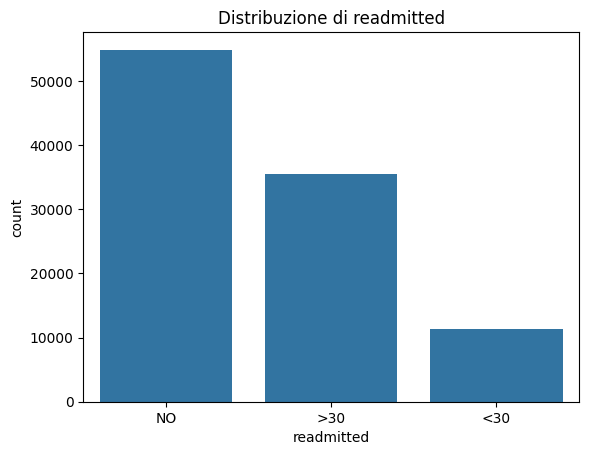

In [3]:
# Proporzioni dei tre valori originali: NO, >30, <30
print(df['readmitted'].value_counts(normalize=True).round(3))

# Target binario: 1 = riammesso entro 30 giorni, 0 = tutto il resto (NO e >30)
df['target'] = (df['readmitted'] == '<30').astype(int)
print('Positivi:', round(df['target'].mean(), 3))

sns.countplot(x='readmitted', data=df)
plt.title('Distribuzione di readmitted')
plt.show()

### Cella 4 — Analisi dei valori mancanti

Calcoliamo la percentuale di valori mancanti di ogni colonna. `weight` manca nel 96,9% dei casi, `max_glu_serum` nel 94,7%, `A1Cresult` nell'83,3%, `medical_specialty` nel 49,1% e `payer_code` nel 39,6%; `race` e i codici diagnostici hanno pochi mancanti. La strategia dipende sia dalla percentuale sia dal motivo per cui il valore manca: per gli esami di laboratorio il mancante significa probabilmente che l'esame non è stato eseguito (MNAR).

weight               96.9
max_glu_serum        94.7
A1Cresult            83.3
medical_specialty    49.1
payer_code           39.6
race                  2.2
diag_3                1.4
diag_2                0.4
diag_1                0.0
dtype: float64


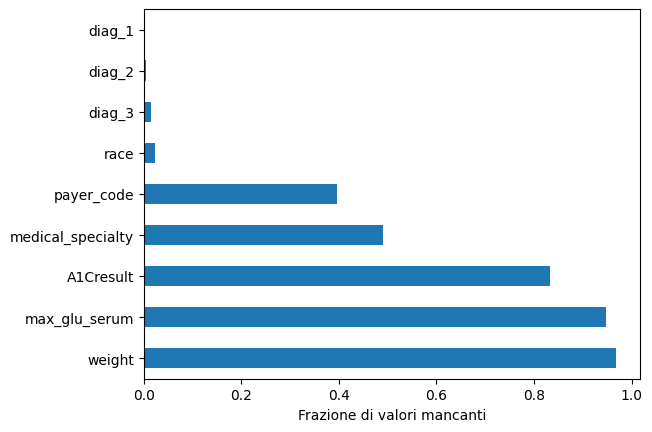

In [4]:
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
print((miss * 100).round(1))

miss.plot.barh()
plt.xlabel('Frazione di valori mancanti')
plt.show()

### Cella 5 — Le due trappole: pazienti ripetuti e dimissioni

Il dataset contiene 101.766 ricoveri ma solo 71.518 pazienti distinti: circa 30.000 righe sono ricoveri ripetuti dello stesso paziente, che dopo lo split causerebbero leakage tra train e test. Inoltre alcune modalità di dimissione (decesso, hospice) rendono impossibile la riammissione. Entrambi i problemi vengono risolti nel preprocessing.

In [5]:
# Ci sono più ricoveri dello stesso paziente? Confronto righe e pazienti distinti
print('Ricoveri:', len(df), '| Pazienti unici:', df['patient_nbr'].nunique())

# Codici di dimissione più frequenti (il loro significato lo ricaviamo nella cella 10)
print(df['discharge_disposition_id'].value_counts().head(10))

Ricoveri: 101766 | Pazienti unici: 71518
discharge_disposition_id
1     60234
3     13954
6     12902
18     3691
2      2128
22     1993
11     1642
5      1184
25      989
4       815
Name: count, dtype: int64


## Parte 2 — Variabili numeriche

### Cella 6 — Statistiche descrittive

Calcoliamo le statistiche descrittive delle otto variabili numeriche. Le colonne `*_id` sono escluse perché, pur contenendo numeri, sono codici di categorie. Le variabili sulle visite precedenti (`number_outpatient`, `number_emergency`, `number_inpatient`) hanno mediana 0 e media più alta: le loro distribuzioni sono fortemente asimmetriche a destra.

In [6]:
# Variabili che misurano una quantità (le colonne *_id sono codici e restano escluse)
num_cols = ['time_in_hospital', 'num_lab_procedures', 'num_procedures',
            'num_medications', 'number_outpatient', 'number_emergency',
            'number_inpatient', 'number_diagnoses']

# count, mean, std, min, 25%, 50% (mediana), 75%, max
df[num_cols].describe().round(2)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00
mean,4.40,43.10,1.34,16.02,0.37,0.20,0.64,7.42
std,2.99,19.67,1.71,8.13,1.27,0.93,1.26,1.93
min,1.00,1.00,0.00,1.00,0.00,0.00,0.00,1.00
25%,2.00,31.00,0.00,10.00,0.00,0.00,0.00,6.00
50%,4.00,44.00,1.00,15.00,0.00,0.00,0.00,8.00
75%,6.00,57.00,2.00,20.00,0.00,0.00,1.00,9.00
max,14.00,132.00,6.00,81.00,42.00,76.00,21.00,16.00


### Cella 7 — Distribuzioni

Visualizziamo la distribuzione di ogni variabile numerica con un istogramma; per le tre variabili concentrate sullo zero usiamo la scala logaritmica, così da rendere visibili anche i valori rari. Emergono due anomalie: un picco vicino a 1 in `num_lab_procedures` e un picco netto a 9 in `number_diagnoses`, probabilmente dovuto a un limite del sistema di registrazione.

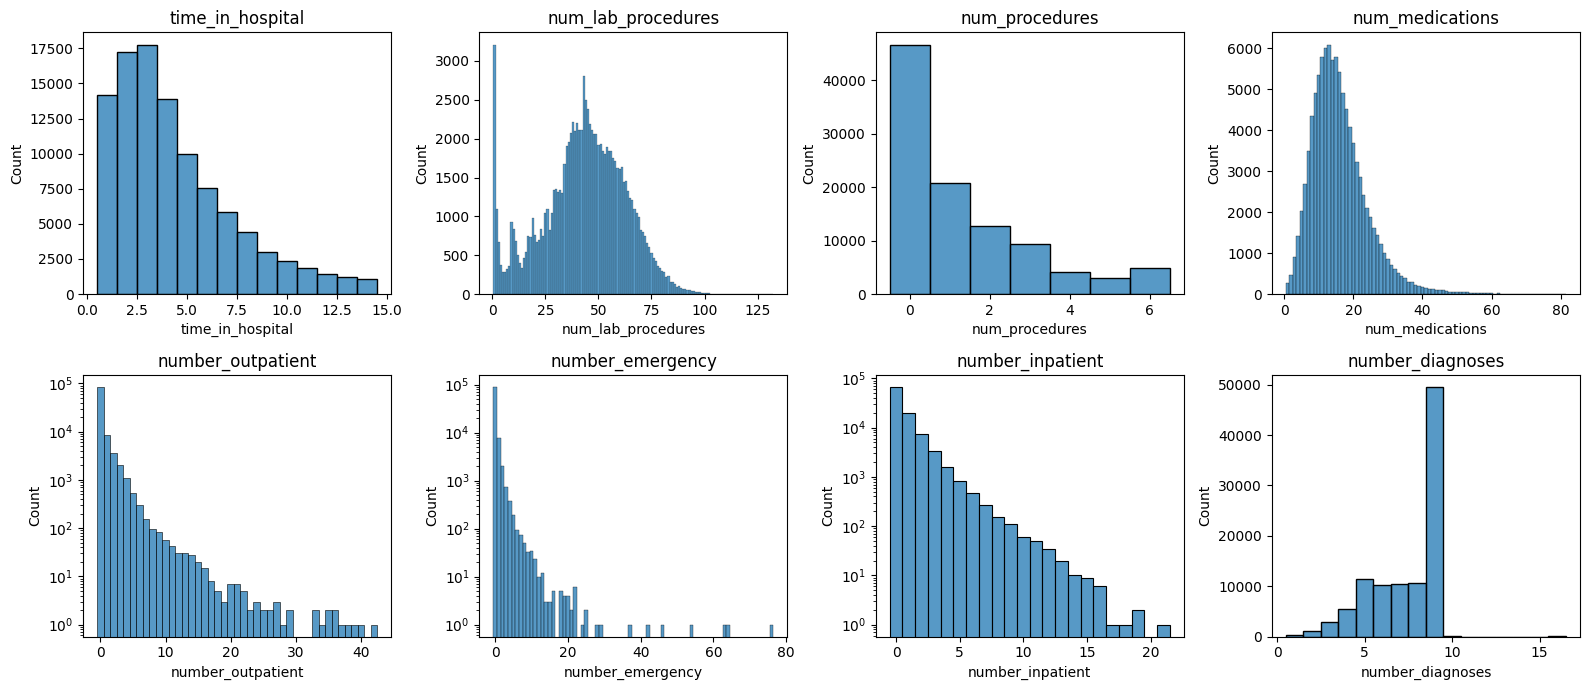

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], discrete=True, ax=ax)
    if col in ['number_outpatient', 'number_emergency', 'number_inpatient']:
        ax.set_yscale('log')
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Cella 8 — Outlier con il metodo IQR (regola di Tukey)

Individuiamo gli outlier con il metodo IQR (regola di Tukey): è outlier ogni valore fuori dall'intervallo [Q1 − 1,5·IQR, Q3 + 1,5·IQR]. Decidiamo di tenerli, perché sono valori rari ma plausibili (ad esempio pazienti con molti accessi al pronto soccorso), non errori. Per le variabili concentrate sullo zero il metodo non è affidabile: con Q1 = Q3 = 0 l'IQR è nullo e qualunque valore diverso da 0 risulta outlier (il 16,4% per `number_outpatient`).

time_in_hospital       2.2
num_lab_procedures     0.1
num_procedures         4.9
num_medications        2.5
number_outpatient     16.4
number_emergency      11.2
number_inpatient       6.9
number_diagnoses       0.3
dtype: float64


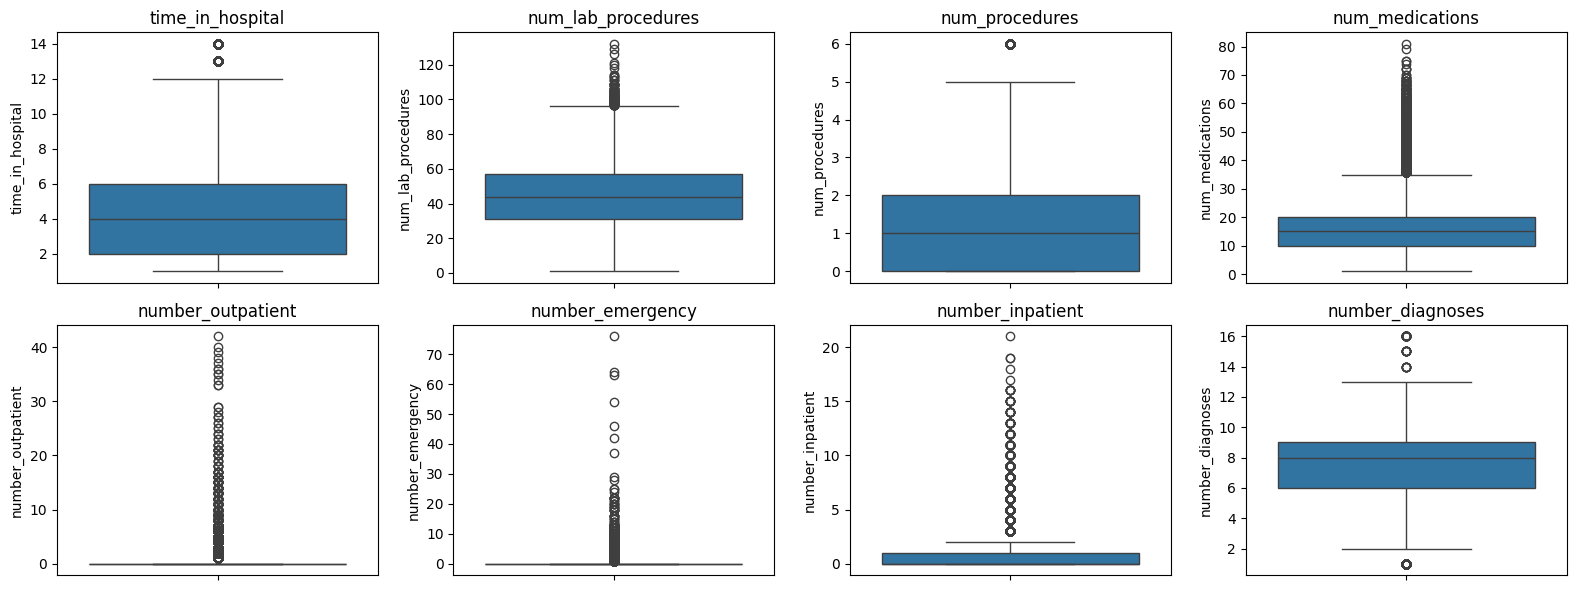

In [8]:
def perc_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    fuori = (s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)
    return fuori.mean() * 100

print(df[num_cols].apply(perc_outlier).round(1))

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Cella 9 — Relazione tra variabili numeriche e target

Confrontiamo le medie delle variabili numeriche tra riammessi e non riammessi. La differenza più forte riguarda `number_inpatient` (1,22 contro 0,56): il tasso di riammissione sale dall'8,4% dei pazienti senza ricoveri precedenti a oltre il 40% di quelli con 8 o 9 ricoveri, anche se questi ultimi gruppi sono piccoli. Anche `number_emergency` raddoppia (0,36 contro 0,18), mentre le altre variabili differiscono poco.

In [9]:
# Media di ogni variabile nei non riammessi (0) e nei riammessi (1)
print(df.groupby('target')[num_cols].mean().round(2).T)

# Tasso di riammissione (mean) e numerosità (count) per numero di ricoveri precedenti
tasso = df.groupby('number_inpatient')['target'].agg(['mean', 'count'])
print(tasso.head(10).round(3))

target                  0      1
time_in_hospital     4.35   4.77
num_lab_procedures  42.95  44.23
num_procedures       1.35   1.28
num_medications     15.91  16.90
number_outpatient    0.36   0.44
number_emergency     0.18   0.36
number_inpatient     0.56   1.22
number_diagnoses     7.39   7.69
                   mean  count
number_inpatient              
0                 0.084  67630
1                 0.129  19521
2                 0.174   7566
3                 0.203   3411
4                 0.236   1622
5                 0.314    812
6                 0.346    480
7                 0.354    268
8                 0.444    151
9                 0.423    111


### Cella 10 — Correlazione tra le variabili numeriche

Verifichiamo se tra le variabili numeriche ci sono coppie fortemente correlate, che porterebbero informazione ridondante. **[DA COMPLETARE dopo l'esecuzione: coppie trovate e decisione presa.]**

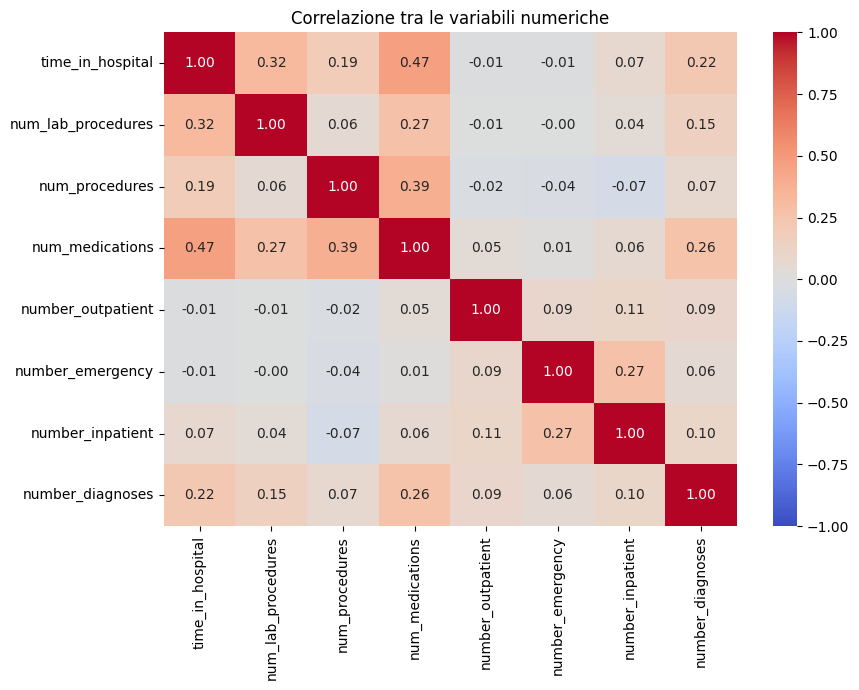

Nessuna coppia con |r| > 0,5


In [10]:
corr = df[num_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlazione tra le variabili numeriche')
plt.tight_layout(); plt.show()

# Coppie con correlazione forte (|r| > 0,5), contando ogni coppia una sola volta
coppie = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
forti = coppie[coppie.abs() > 0.5].sort_values(ascending=False)
print(forti if len(forti) else 'Nessuna coppia con |r| > 0,5')

## Parte 3 — Variabili categoriche

### Cella 11 — Decodifica dei codici ID

I codici di `admission_type_id`, `discharge_disposition_id` e `admission_source_id` sono numeri senza significato proprio: li traduciamo nelle loro descrizioni usando il file `IDS_mapping.csv` fornito con il dataset. Sono variabili categoriche nominali, quindi non vanno trattate come numeri. La decodifica rivela anche dei missing mascherati, come "NULL", "Not Available" e "Not Mapped".

In [11]:
import glob

# Scarica ed estrae lo zip ufficiale UCI, che contiene IDS_mapping.csv
!wget -q -O diab.zip "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"
!unzip -o -q diab.zip -d diab
path = glob.glob('diab/**/IDS_mapping.csv', recursive=True)[0]

mappe, corrente = {}, None
for riga in open(path):
    riga = riga.strip()
    if not riga or riga == ',':
        continue
    codice, descr = riga.split(',', 1)
    if codice.endswith('_id'):
        corrente = codice
        mappe[corrente] = {}
    else:
        mappe[corrente][int(codice)] = descr.strip('"')

for col, mappa in mappe.items():
    df[col + '_desc'] = df[col].map(mappa)
print(df[['admission_type_id', 'admission_type_id_desc']].drop_duplicates())

       admission_type_id admission_type_id_desc
0                      6                   NULL
1                      1              Emergency
5                      2                 Urgent
6                      3               Elective
2043                   4                Newborn
3089                   5          Not Available
7789                   8             Not Mapped
45829                  7          Trauma Center


### Cella 12 — Relazione tra variabili categoriche e target

Per alcune variabili categoriche calcoliamo il numero di ricoveri e la percentuale di riammessi per ogni valore, considerando i mancanti come un gruppo a sé. I ricoveri senza `A1Cresult` hanno l'11,4% di riammessi, contro il 9,7–10,0% di quelli in cui l'esame è stato eseguito: il mancante porta informazione, a conferma dell'ipotesi MNAR. Per `max_glu_serum` la riammissione cresce con il valore del glucosio (14,3% per >300). Alcune categorie sono troppo piccole per essere interpretate (Trauma Center: 21 ricoveri).

In [12]:
def analisi_cat(col, top=15):
    # Per ogni valore della colonna: numero di ricoveri e quota di riammessi
    t = df.groupby(col, dropna=False)['target'].agg(['count', 'mean'])
    t['mean'] = (t['mean'] * 100).round(1)
    t.columns = ['n_pazienti', '%_riammessi']
    return t.sort_values('n_pazienti', ascending=False).head(top)

for col in ['admission_type_id_desc', 'age', 'A1Cresult', 'max_glu_serum', 'race']:
    print(analisi_cat(col), '\n')

                        n_pazienti  %_riammessi
admission_type_id_desc                         
Emergency                    53990         11.5
Elective                     18869         10.4
Urgent                       18480         11.2
NULL                          5291         11.1
Not Available                 4785         10.3
Not Mapped                     320          8.4
Trauma Center                   21          0.0
Newborn                         10         10.0 

          n_pazienti  %_riammessi
age                              
[70-80)        26068         11.8
[60-70)        22483         11.1
[50-60)        17256          9.7
[80-90)        17197         12.1
[40-50)         9685         10.6
[30-40)         3775         11.2
[90-100)        2793         11.1
[20-30)         1657         14.2
[10-20)          691          5.8
[0-10)           161          1.9 

           n_pazienti  %_riammessi
A1Cresult                         
NaN             84748         11.4
>8 

### Cella 13 — Modalità di dimissione

Analizziamo le modalità di dimissione. I pazienti deceduti ("Expired", 1.642 ricoveri) hanno lo 0% di riammissioni e quelli in hospice tassi molto bassi: non possono essere riammessi, quindi li rimuoveremo. La dimissione è anche una delle variabili più informative: chi viene trasferito in riabilitazione viene riammesso nel 27,7% dei casi, chi torna a casa nel 9,3%.

In [13]:
print(analisi_cat('discharge_disposition_id_desc', top=30))

                                                    n_pazienti  %_riammessi
discharge_disposition_id_desc                                              
Discharged to home                                       60234          9.3
Discharged/transferred to SNF                            13954         14.7
Discharged/transferred to home with home health...       12902         12.7
NULL                                                      3691         12.4
Discharged/transferred to another short term ho...        2128         16.1
Discharged/transferred to another rehab fac inc...        1993         27.7
Expired                                                   1642          0.0
Discharged/transferred to another type of inpat...        1184         20.9
Not Mapped                                                 989          9.3
Discharged/transferred to ICF                              815         12.8
Left AMA                                                   623         14.4
Discharged/t

### Cella 14 — Cardinalità delle variabili categoriche

Contiamo i valori distinti delle variabili testuali. I codici diagnostici (`diag_1`, `diag_2`, `diag_3`) superano i 700 valori e `medical_specialty` ne ha 72: andranno raggruppati, per evitare centinaia di colonne con il one-hot encoding. `examide` e `citoglipton` hanno un solo valore: sono costanti, non distinguono nessun paziente e vanno eliminate.

In [14]:
cat_cols = df.select_dtypes('object').columns
print(df[cat_cols].nunique().sort_values(ascending=False).to_string())

diag_3                           789
diag_2                           748
diag_1                           716
medical_specialty                 72
discharge_disposition_id_desc     26
admission_source_id_desc          17
payer_code                        17
age                               10
weight                             9
admission_type_id_desc             8
race                               5
insulin                            4
chlorpropamide                     4
metformin                          4
nateglinide                        4
repaglinide                        4
acarbose                           4
miglitol                           4
rosiglitazone                      4
pioglitazone                       4
glyburide-metformin                4
glimepiride                        4
glyburide                          4
glipizide                          4
gender                             3
readmitted                         3
A1Cresult                          3
m

## Parte 4 — Preprocessing

Prima dello split train/test applichiamo solo trasformazioni a regola fissa, uguali per ogni riga. Le operazioni che imparano dai dati (scaling, bilanciamento, scelta degli iperparametri) vengono eseguite dopo lo split, usando solo il train.

### Cella 15 — Rimozione delle righe

Questa cella elimina le righe che falserebbero il modello. Rimuoviamo i ricoveri terminati con il decesso o in hospice: questi pazienti non possono essere riammessi, quindi il loro target sarebbe 0 per forza. Per i pazienti con più ricoveri ne teniamo solo uno, il primo, perché lo stesso paziente presente sia nel train sia nel test causerebbe leakage. I codici di dimissione da escludere vengono selezionati con `.isin()`, mentre i ricoveri ripetuti vengono rimossi con `drop_duplicates()`. Alla fine ogni riga corrisponde a un paziente diverso: le righe passano da 101.766 a 69.987 e la quota di positivi scende dall’11,2% al 9,0%, perché i pazienti con molti ricoveri sono proprio quelli che vengono riammessi più spesso.

In [15]:
n0, p0 = len(df), df['target'].mean()

# 1) Deceduti (codici 11, 19, 20, 21) e hospice (13, 14): non possono essere riammessi
esclusi = [11, 13, 14, 19, 20, 21]
df = df[~df['discharge_disposition_id'].isin(esclusi)]

# 2) Genere "Unknown/Invalid": pochissime righe, nessuna informazione utile
df = df[df['gender'] != 'Unknown/Invalid']

# 3) Un solo ricovero per paziente: ordino per ID del ricovero e tengo il primo
df = df.sort_values('encounter_id').drop_duplicates(subset='patient_nbr', keep='first')

print(f'Righe: {n0} -> {len(df)}  |  Positivi: {p0:.3f} -> {df["target"].mean():.3f}')

Righe: 101766 -> 69987  |  Positivi: 0.112 -> 0.090


### Cella 16 — Eliminazione delle colonne

In questa cella eliminiamo le colonne superflue. Rimuoviamo gli identificativi, perché il modello memorizzerebbe i pazienti invece di imparare; `weight` e `payer_code`, che hanno troppi valori mancanti; i farmaci usati da meno dello 0,5% dei pazienti, che sono quasi costanti. Soprattutto rimuoviamo la colonna `readmitted`, che contiene il valore che vogliamo prevedere: lasciarla sarebbe leakage puro. In questo modo riduciamo il rumore ed evitiamo calcoli su pattern che sappiamo non essere importanti.

In [16]:
farmaci = ['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride',
           'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone',
           'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide',
           'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin',
           'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']

uso = (df[farmaci] != 'No').mean()
farmaci_rari = uso[uso < 0.005].index.tolist()
print('Farmaci quasi costanti eliminati:', farmaci_rari)

da_eliminare = (['encounter_id', 'patient_nbr',
                 'weight', 'payer_code',
                 'readmitted',
                 'admission_type_id', 'discharge_disposition_id',
                 'admission_source_id']
                + farmaci_rari)
df = df.drop(columns=da_eliminare)

farmaci = [f for f in farmaci if f not in farmaci_rari]
print(df.shape)

Farmaci quasi costanti eliminati: ['chlorpropamide', 'acetohexamide', 'tolbutamide', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']
(69987, 33)


### Cella 17 — Gestione dei valori mancanti

In questa cella gestiamo i valori mancanti, trasformando ognuno in una categoria esplicita (“Non misurato” o “Unknown”). Non imputiamo con la moda perché qui il mancante è informativo: per `A1Cresult` e `max_glu_serum` significa che l’esame non è stato eseguito (MNAR), e la moda cancellerebbe questo segnale. Così arriviamo a zero missing senza eliminare righe né informazioni.

In [17]:
# A1C e glucosio: mancante = "esame non eseguito" (MNAR) -> diventa una categoria
df[['A1Cresult', 'max_glu_serum']] = df[['A1Cresult', 'max_glu_serum']].fillna('Non misurato')

# race e medical_specialty: mancante -> categoria "Unknown"
df[['race', 'medical_specialty']] = df[['race', 'medical_specialty']].fillna('Unknown')

# Colonne _desc: le voci che significano "non disponibile" sono missing mascherati
col_id = ['admission_type_id_desc', 'discharge_disposition_id_desc', 'admission_source_id_desc']
etichette_mancanti = ['NULL', 'Not Available', 'Not Mapped', 'Unknown/Invalid']
for col in col_id:
    df[col] = df[col].str.strip()
    df[col] = df[col].replace(etichette_mancanti, 'Unknown').fillna('Unknown')

### Cella 18 — Raggruppamento delle categorie

In questa cella raggruppiamo le categorie. I codici diagnostici, oltre 700, vengono divisi in circa 9 gruppi clinici seguendo il paper originale del dataset; nelle altre colonne, le categorie presenti in meno dell’1% dei pazienti diventano “Altro”. Raggruppiamo perché molti codici compaiono in pochissimi pazienti, e ogni colonna rara aumenta la dimensionalità senza dare al modello abbastanza esempi per imparare. Il risultato sono poche colonne, più stabili e interpretabili.

In [18]:
def gruppo_icd9(codice):
    if pd.isna(codice):
        return 'Missing'
    codice = str(codice)
    if codice.startswith(('V', 'E')):
        return 'Altro'
    n = int(float(codice))
    if 390 <= n <= 459 or n == 785: return 'Circolatorio'
    if 460 <= n <= 519 or n == 786: return 'Respiratorio'
    if 520 <= n <= 579 or n == 787: return 'Digerente'
    if n == 250:                     return 'Diabete'
    if 800 <= n <= 999:              return 'Traumi'
    if 710 <= n <= 739:              return 'Muscoloscheletrico'
    if 580 <= n <= 629 or n == 788: return 'Genitourinario'
    if 140 <= n <= 239:              return 'Neoplasie'
    return 'Altro'

for col in ['diag_1', 'diag_2', 'diag_3']:
    df[col] = df[col].apply(gruppo_icd9)

def raggruppa_rare(serie, soglia=0.01):
    quote = serie.value_counts(normalize=True)
    rare = quote[quote < soglia].index
    return serie.where(~serie.isin(rare), 'Altro')

for col in ['medical_specialty'] + col_id:
    df[col] = raggruppa_rare(df[col])
    print(col, '->', df[col].nunique(), 'categorie')

medical_specialty -> 11 categorie
admission_type_id_desc -> 5 categorie
discharge_disposition_id_desc -> 8 categorie
admission_source_id_desc -> 7 categorie


### Cella 19 — Encoding: da categorie a numeri

In questa cella convertiamo tutte le colonne in numeri, perché i modelli accettano solo valori numerici. L’età è divisa in fasce che hanno un ordine, quindi usiamo la codifica ordinale (da 0 a 9). Le variabili binarie, come il genere, diventano 0/1. Le variabili nominali, che non hanno un ordine (per esempio il tipo di ricovero), vengono codificate con il one-hot encoding: una colonna 0/1 per ogni categoria, così il modello non impara relazioni inesistenti tra le categorie.

In [19]:
# Età: ordinale -> numero della fascia (0 = [0-10), 1 = [10-20), ..., 9 = [90-100))
df['age'] = df['age'].str.extract(r'\[(\d+)')[0].astype(int) // 10

# Variabili binarie -> 0/1
df['gender'] = (df['gender'] == 'Male').astype(int)
df['change'] = (df['change'] == 'Ch').astype(int)
df['diabetesMed'] = (df['diabetesMed'] == 'Yes').astype(int)

# Farmaci: 1 se assunto (Steady/Up/Down), 0 se "No"
for f in farmaci:
    df[f] = (df[f] != 'No').astype(int)

# Categoriche nominali -> one-hot (una colonna 0/1 per ogni categoria)
nominali = ['race', 'medical_specialty', 'A1Cresult', 'max_glu_serum',
            'diag_1', 'diag_2', 'diag_3'] + col_id
df = pd.get_dummies(df, columns=nominali, dtype=int)
print(df.shape)

(69987, 98)


### Cella 20 — Controllo finale del preprocessing

Controlliamo di essere riusciti a ottenere quello che volevamo: zero valori mancanti, nessuna colonna testuale, le dimensioni finali del dataset (69.987 righe e 98 colonne) e la percentuale di positivi (9%).

In [20]:
print('Valori mancanti rimasti:', df.isna().sum().sum())
print('Colonne non numeriche:', df.select_dtypes('object').columns.tolist())
print('Shape finale:', df.shape, '| Positivi:', round(df['target'].mean(), 3))

Valori mancanti rimasti: 0
Colonne non numeriche: []
Shape finale: (69987, 98) | Positivi: 0.09


## Parte 5 — Split, scaling e primi modelli

### Cella 21 — Split train/test stratificato

Separiamo i dati in train e test con una proporzione 80/20, così il modello viene valutato su pazienti che non ha mai visto. Lo split è stratificato: in questo modo la percentuale di positivi è uguale in entrambi i sottoinsiemi (circa 9%).

In [21]:
from sklearn.model_selection import train_test_split

X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42)

print('Train:', X_train.shape, '| positivi:', round(y_train.mean(), 3))
print('Test: ', X_test.shape, '| positivi:', round(y_test.mean(), 3))

Train: (55989, 97) | positivi: 0.09
Test:  (13998, 97) | positivi: 0.09


### Cella 22 — Scaling (standardizzazione)

Standardizziamo le variabili numeriche e l'età (le colonne 0/1 del one-hot restano invariate). Se le lasciassimo nella forma originale, avrebbero scale troppo diverse e alcuni modelli verrebbero falsati, perché le variabili con valori grandi peserebbero di più. Media e deviazione standard vengono calcolate solo sul train e poi applicate al test, per evitare leakage.

In [22]:
from sklearn.preprocessing import StandardScaler

da_scalare = num_cols + ['age']

scaler = StandardScaler()
X_train_sc, X_test_sc = X_train.copy(), X_test.copy()
X_train_sc[da_scalare] = scaler.fit_transform(X_train[da_scalare])
X_test_sc[da_scalare] = scaler.transform(X_test[da_scalare])

print(X_train_sc[da_scalare].describe().loc[['mean', 'std']].round(2))

      time_in_hospital  num_lab_procedures  num_procedures  num_medications  \
mean               0.0                -0.0            -0.0             -0.0   
std                1.0                 1.0             1.0              1.0   

      number_outpatient  number_emergency  number_inpatient  number_diagnoses  \
mean               -0.0              -0.0              -0.0              -0.0   
std                 1.0               1.0               1.0               1.0   

      age  
mean  0.0  
std   1.0  


### Cella 23 — Funzione di valutazione

Definiamo una funzione di valutazione basata su sei metriche (accuracy, precision, recall, F1, ROC-AUC e PR-AUC), che mostra anche la matrice di confusione. Con classi sbilanciate l'accuracy da sola non basta, quindi servono metriche centrate sulla classe positiva. La funzione verrà usata per valutare tutti i modelli nello stesso modo.

In [23]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, ConfusionMatrixDisplay)

risultati = {}

def valuta(nome, modello, X_te, y_te):
    y_pred = modello.predict(X_te)
    y_prob = modello.predict_proba(X_te)[:, 1]
    risultati[nome] = {
        'Accuracy':  accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, zero_division=0),
        'Recall':    recall_score(y_te, y_pred),
        'F1':        f1_score(y_te, y_pred),
        'ROC-AUC':   roc_auc_score(y_te, y_prob),
        'PR-AUC':    average_precision_score(y_te, y_prob)}
    ConfusionMatrixDisplay.from_predictions(y_te, y_pred, cmap='Blues')
    plt.title(nome); plt.show()
    return pd.DataFrame(risultati).T.round(3)

### Cella 24 — Baseline: Dummy Classifier

La baseline è data da un classificatore dummy che risponde sempre "non riammesso". Serve come punto di riferimento minimo: un modello ha senso solo se fa meglio di questo. Inoltre mostra che qui l'accuracy non ha senso: misura le previsioni corrette su entrambe le classi, ma con il 91% di negativi un modello che risponde sempre "no" ottiene un'accuracy del 91% senza riconoscere nessun paziente riammesso.

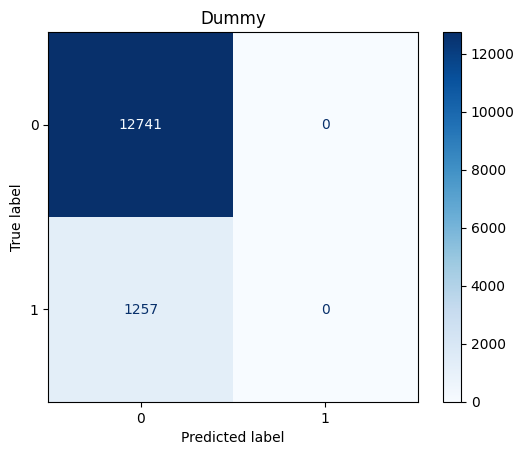

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Dummy,0.91,0.0,0.0,0.0,0.5,0.09


In [24]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
valuta('Dummy', dummy, X_test, y_test)

### Cella 25 — Decision Tree senza vincoli (overfitting)

Addestriamo un albero senza vincoli, che cresce finché ogni foglia contiene una sola classe (foglie pure), memorizzando il train: arriva a 44 livelli e 6.780 foglie. Il risultato mostra l'overfitting: F1 di 1,0 sul train contro 0,15 sul test, con una ROC-AUC di 0,53, vicina al caso. Questo giustifica i vincoli impostati nell'albero successivo.

Profondità raggiunta: 44 | foglie: 6780
F1 train: 1.0


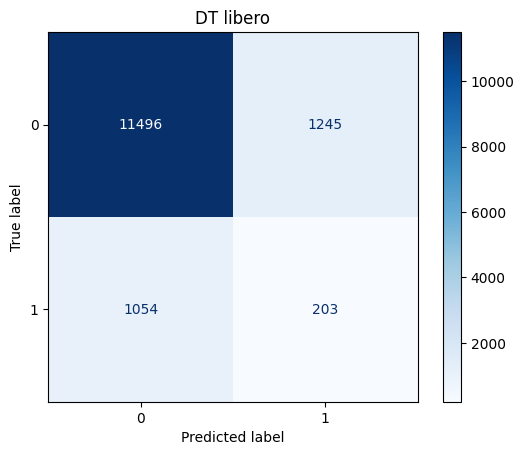

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Dummy,0.910,0.00,0.000,0.00,0.500,0.090
DT libero,0.836,0.14,0.161,0.15,0.532,0.098


In [25]:
from sklearn.tree import DecisionTreeClassifier

dt_libero = DecisionTreeClassifier(random_state=42)
dt_libero.fit(X_train, y_train)

print('Profondità raggiunta:', dt_libero.get_depth(), '| foglie:', dt_libero.get_n_leaves())
print('F1 train:', round(f1_score(y_train, dt_libero.predict(X_train)), 3))
valuta('DT libero', dt_libero, X_test, y_test)

### Cella 26 — Decision Tree limitato e bilanciato

Addestriamo un albero con vincoli di complessità (profondità massima 6, almeno 50 pazienti per foglia) e con i pesi delle classi bilanciati. I vincoli impediscono all'albero di memorizzare il train, mentre i pesi lo obbligano a tenere conto della classe minoritaria. Il modello riconosce il 57% dei riammessi, contro lo 0% del dummy, senza overfitting (F1 0,22 sul train e 0,21 sul test). Il prezzo è una precision bassa (12,7%): molti pazienti segnalati non vengono poi riammessi.

F1 train: 0.218


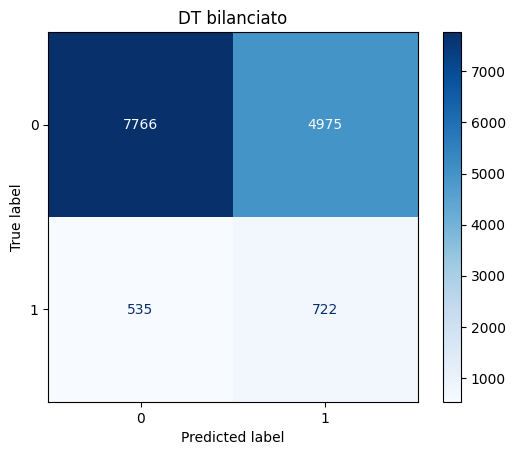

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Dummy,0.910,0.000,0.000,0.000,0.500,0.090
DT libero,0.836,0.140,0.161,0.150,0.532,0.098
DT bilanciato,0.606,0.127,0.574,0.208,0.632,0.159


In [26]:
dt = DecisionTreeClassifier(
    max_depth=6,
    min_samples_leaf=50,
    class_weight='balanced',
    random_state=42)
dt.fit(X_train, y_train)

print('F1 train:', round(f1_score(y_train, dt.predict(X_train)), 3))
valuta('DT bilanciato', dt, X_test, y_test)

## Parte 6 — Ottimizzazione e confronto dei modelli

### Cella 27 — Cross-validation e ottimizzazione del Decision Tree

Proviamo 16 combinazioni di iperparametri, le valutiamo con una cross-validation a 5 fold sul solo train e infine valutiamo sul test l'albero migliore. Otteniamo così un albero ottimizzato con una procedura difendibile e una stima delle prestazioni che non usa il test: poiché gli iperparametri vengono scelti senza guardarlo, la stima finale non risulta ottimistica. L'albero migliore ha profondità 6 e almeno 100 pazienti per foglia, con un miglioramento minimo rispetto alla versione precedente (PR-AUC da 0,159 a 0,164).

Migliori iperparametri: {'max_depth': 6, 'min_samples_leaf': 100}
PR-AUC media in CV: 0.151


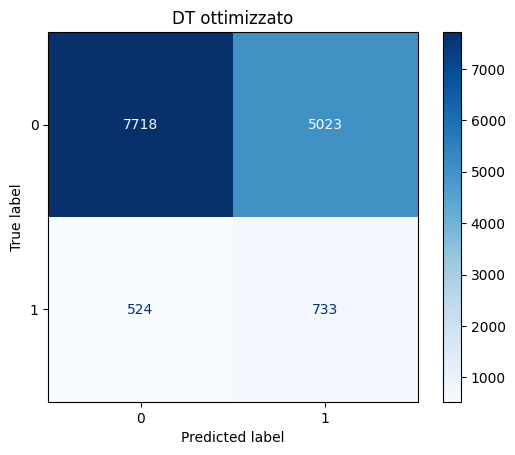

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Dummy,0.910,0.000,0.000,0.000,0.500,0.090
DT libero,0.836,0.140,0.161,0.150,0.532,0.098
DT bilanciato,0.606,0.127,0.574,0.208,0.632,0.159
DT ottimizzato,0.604,0.127,0.583,0.209,0.638,0.164


In [27]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

griglia_dt = {'max_depth': [4, 6, 8, 10],
              'min_samples_leaf': [20, 50, 100, 200]}

ricerca_dt = GridSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=42),
    griglia_dt,
    scoring='average_precision',
    cv=cv, n_jobs=-1)
ricerca_dt.fit(X_train, y_train)

print('Migliori iperparametri:', ricerca_dt.best_params_)
print('PR-AUC media in CV:', round(ricerca_dt.best_score_, 3))
dt_best = ricerca_dt.best_estimator_
valuta('DT ottimizzato', dt_best, X_test, y_test)

### Cella 28 — Logistic Regression

Addestriamo una regressione logistica con i pesi delle classi bilanciati, sui dati scalati, scegliendo con la cross-validation la forza della regolarizzazione (C). È il modello lineare di riferimento per la classificazione binaria: semplice, veloce, interpretabile e un buon termine di confronto per gli alberi. Il valore migliore è C = 10, con una PR-AUC di 0,165 sul test, leggermente superiore all'albero.

Miglior C: {'C': 10} | PR-AUC in CV: 0.161


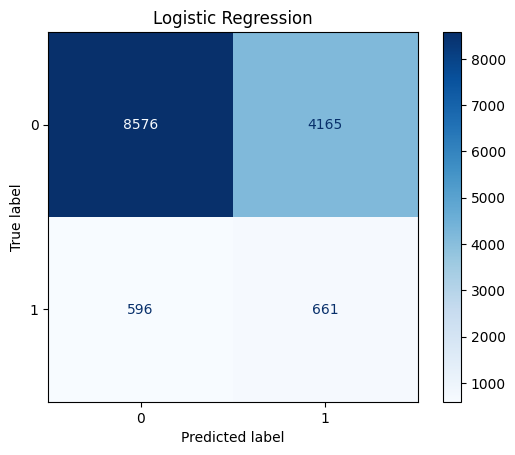

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Dummy,0.910,0.000,0.000,0.000,0.500,0.090
DT libero,0.836,0.140,0.161,0.150,0.532,0.098
DT bilanciato,0.606,0.127,0.574,0.208,0.632,0.159
DT ottimizzato,0.604,0.127,0.583,0.209,0.638,0.164
Logistic Regression,0.660,0.137,0.526,0.217,0.647,0.165


In [28]:
from sklearn.linear_model import LogisticRegression

ricerca_lr = GridSearchCV(
    LogisticRegression(class_weight='balanced', max_iter=1000),
    {'C': [0.01, 0.1, 1, 10]},
    scoring='average_precision', cv=cv, n_jobs=-1)
ricerca_lr.fit(X_train_sc, y_train)

print('Miglior C:', ricerca_lr.best_params_, '| PR-AUC in CV:', round(ricerca_lr.best_score_, 3))
lr = ricerca_lr.best_estimator_
valuta('Logistic Regression', lr, X_test_sc, y_test)

### Cella 29 — Random Forest

Utilizziamo una Random Forest di 200 alberi invece di uno solo. Un singolo albero è instabile: piccoli cambiamenti nei dati producono alberi molto diversi. Nella Random Forest ogni albero viene addestrato su un campione diverso del train e, a ogni split, su un sottoinsieme casuale di feature (bagging); la previsione finale è la media dei 200 alberi, che riduce la varianza. Verifichiamo così se un modello ensemble, cioè l'unione di più modelli, migliora rispetto al singolo albero. È il modello migliore: PR-AUC 0,176 e ROC-AUC 0,654.

Migliori iperparametri: {'max_depth': 12, 'min_samples_leaf': 20} | PR-AUC in CV: 0.169


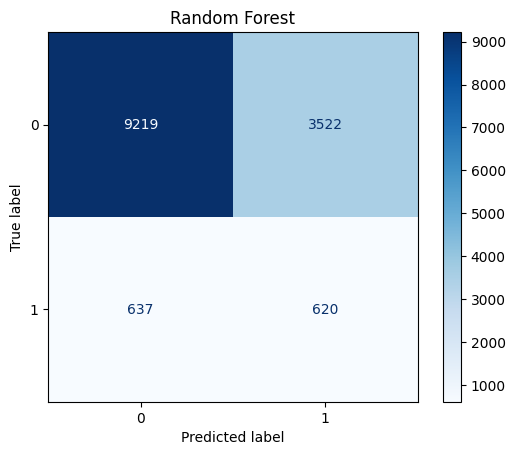

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Dummy,0.910,0.000,0.000,0.000,0.500,0.090
DT libero,0.836,0.140,0.161,0.150,0.532,0.098
DT bilanciato,0.606,0.127,0.574,0.208,0.632,0.159
DT ottimizzato,0.604,0.127,0.583,0.209,0.638,0.164
Logistic Regression,0.660,0.137,0.526,0.217,0.647,0.165
Random Forest,0.703,0.150,0.493,0.230,0.654,0.176


In [29]:
from sklearn.ensemble import RandomForestClassifier

ricerca_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=200,
                           class_weight='balanced_subsample',
                           random_state=42, n_jobs=-1),
    {'max_depth': [8, 12], 'min_samples_leaf': [20, 50]},
    scoring='average_precision',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42))
ricerca_rf.fit(X_train, y_train)

print('Migliori iperparametri:', ricerca_rf.best_params_, '| PR-AUC in CV:', round(ricerca_rf.best_score_, 3))
rf = ricerca_rf.best_estimator_
valuta('Random Forest', rf, X_test, y_test)

### Cella 30 — Tecnica data-level: SMOTE

Invece dei pesi delle classi, proviamo SMOTE, che crea esempi sintetici della classe minoritaria: confrontiamo così una tecnica data-level con una algorithm-level. SMOTE è inserito in una pipeline, in modo da essere applicato solo ai fold di addestramento e mai alla validazione o al test, evitando il leakage. Il risultato è peggiore: PR-AUC in CV di 0,151 contro 0,161 con i pesi, e alla soglia 0,5 il modello non segnala quasi nessun paziente (recall 0,005). Per questo manteniamo i pesi delle classi.

PR-AUC in CV con SMOTE: 0.151 | con class_weight: 0.161


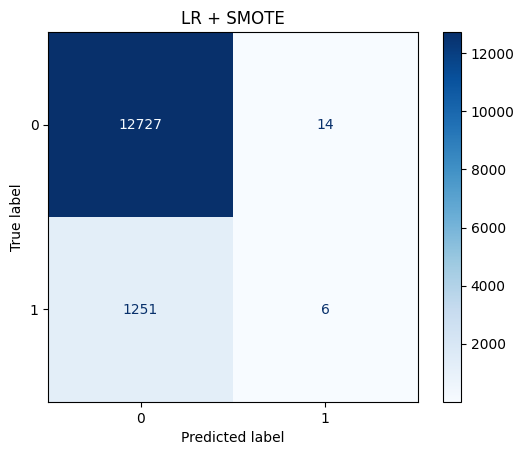

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Dummy,0.910,0.000,0.000,0.000,0.500,0.090
DT libero,0.836,0.140,0.161,0.150,0.532,0.098
DT bilanciato,0.606,0.127,0.574,0.208,0.632,0.159
DT ottimizzato,0.604,0.127,0.583,0.209,0.638,0.164
Logistic Regression,0.660,0.137,0.526,0.217,0.647,0.165
Random Forest,0.703,0.150,0.493,0.230,0.654,0.176
LR + SMOTE,0.910,0.300,0.005,0.009,0.621,0.151


In [30]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

lr_smote = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('lr', LogisticRegression(C=ricerca_lr.best_params_['C'], max_iter=1000))])

cv_smote = cross_val_score(lr_smote, X_train_sc, y_train, cv=cv,
                           scoring='average_precision', n_jobs=-1)
print('PR-AUC in CV con SMOTE:', round(cv_smote.mean(), 3),
      '| con class_weight:', round(ricerca_lr.best_score_, 3))

lr_smote.fit(X_train_sc, y_train)
valuta('LR + SMOTE', lr_smote, X_test_sc, y_test)

### Cella 31 — Diagnosi del comportamento di SMOTE

Verifichiamo perché il modello con SMOTE non segnala quasi nessun paziente. Sui pazienti reali la probabilità media è molto bassa (0,137 per i positivi, 0,104 per i negativi), sia nel train sia nel test. Poiché sui dati bilanciati la probabilità media dovrebbe essere circa 0,5, sono i positivi sintetici a ricevere probabilità altissime: il modello ha imparato a distinguere i punti sintetici da quelli reali, non a riconoscere i pazienti a rischio. Il motivo è che SMOTE, interpolando su colonne one-hot e conteggi interi, genera valori che nessun paziente reale può avere. Per questo manteniamo i pesi delle classi.

In [31]:
# Quota di previsti positivi e probabilità media, calcolate SOLO su pazienti reali
for nome, X_, y_ in [('Train (reali)', X_train_sc, y_train), ('Test', X_test_sc, y_test)]:
    p = lr_smote.predict_proba(X_)[:, 1]
    pos, neg = p[y_.values == 1], p[y_.values == 0]
    print(f'{nome}: previsti positivi {(p >= 0.5).mean():.3f} | '
          f'prob. media positivi {pos.mean():.3f} | negativi {neg.mean():.3f}')

Train (reali): previsti positivi 0.001 | prob. media positivi 0.137 | negativi 0.104
Test: previsti positivi 0.001 | prob. media positivi 0.136 | negativi 0.104


## Parte 7 — Valutazione finale e analisi degli errori

### Cella 32 — Curve ROC e precision-recall a confronto

Confrontiamo i tre modelli ottimizzati con le curve ROC e precision-recall, che mostrano il loro comportamento su tutte le soglie. La Random Forest ha l'area maggiore in entrambi i grafici (ROC-AUC 0,654, PR-AUC 0,176), ma le differenze tra i modelli sono piccole e tutti restano lontani da un classificatore ideale. Nella curva precision-recall il riferimento casuale è la quota di positivi (0,09).

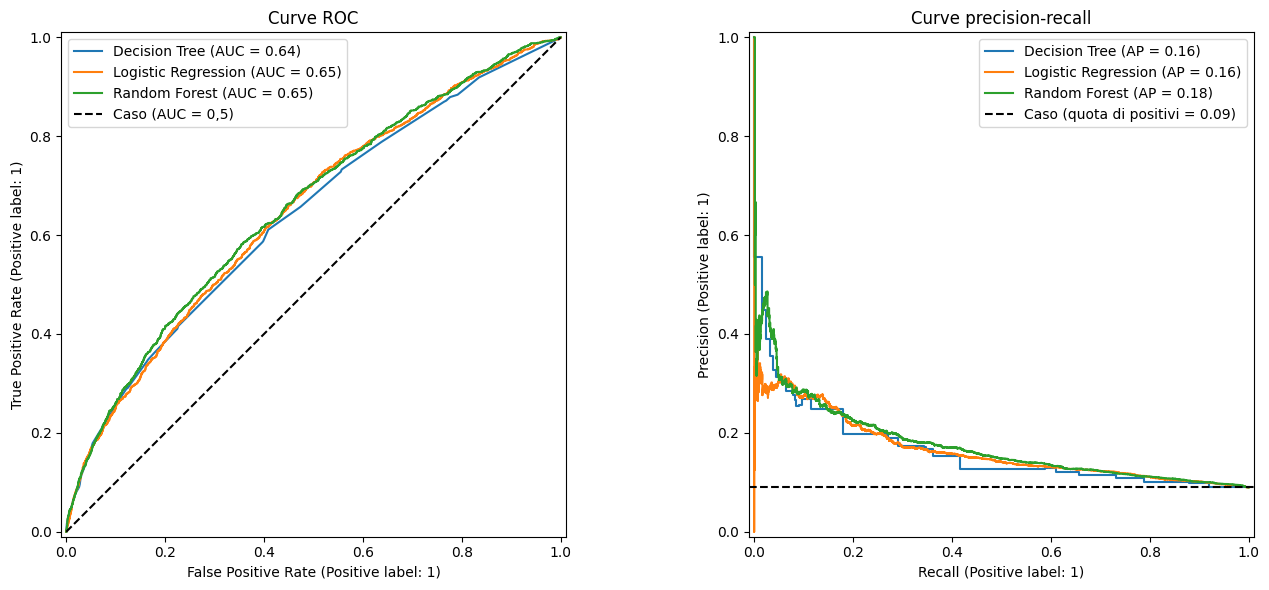

In [32]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

modelli = {'Decision Tree': (dt_best, X_test),
           'Logistic Regression': (lr, X_test_sc),
           'Random Forest': (rf, X_test)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
for nome, (m, X_) in modelli.items():
    RocCurveDisplay.from_estimator(m, X_, y_test, name=nome, ax=ax1)
    PrecisionRecallDisplay.from_estimator(m, X_, y_test, name=nome, ax=ax2)
ax1.plot([0, 1], [0, 1], 'k--', label='Caso (AUC = 0,5)')
ax2.axhline(y_test.mean(), color='k', linestyle='--',
            label=f'Caso (quota di positivi = {y_test.mean():.2f})')
ax1.set_title('Curve ROC'); ax2.set_title('Curve precision-recall')
ax1.legend(); ax2.legend()
plt.tight_layout(); plt.show()

### Cella 33 — Scelta della soglia di classificazione

La soglia di 0,5 è solo una convenzione, quindi scegliamo la soglia della Random Forest in base al costo degli errori. Poiché perdere un paziente che verrà riammesso è più grave di un falso allarme, usiamo l'F2, che pesa la recall il doppio della precision. Per non usare il test, la soglia viene scelta sulle previsioni ottenute in cross-validation sul train: la soglia scelta è 0,431, con una recall di 0,714 e una precision di 0,122.

Soglia scelta: 0.431 | precision 0.122 | recall 0.714 | F2 0.363


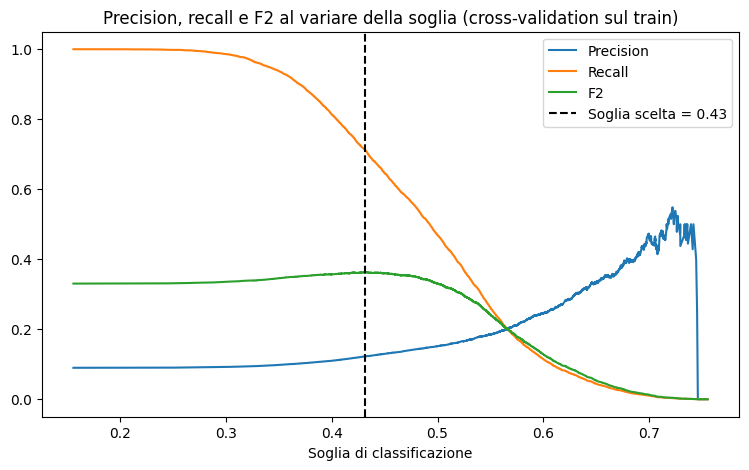

In [33]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

# Probabilità "fuori fold": ogni paziente del train è previsto da un modello che non l'ha visto
p_oof = cross_val_predict(rf, X_train, y_train, method='predict_proba',
                          cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42))[:, 1]

prec, rec, soglie = precision_recall_curve(y_train, p_oof)
beta = 2
f2 = (1 + beta**2) * prec * rec / (beta**2 * prec + rec + 1e-12)
i = np.argmax(f2[:-1])
soglia = soglie[i]
print(f'Soglia scelta: {soglia:.3f} | precision {prec[i]:.3f} | recall {rec[i]:.3f} | F2 {f2[i]:.3f}')

plt.figure(figsize=(9, 5))
plt.plot(soglie, prec[:-1], label='Precision')
plt.plot(soglie, rec[:-1], label='Recall')
plt.plot(soglie, f2[:-1], label='F2')
plt.axvline(soglia, color='k', linestyle='--', label=f'Soglia scelta = {soglia:.2f}')
plt.xlabel('Soglia di classificazione'); plt.legend()
plt.title('Precision, recall e F2 al variare della soglia (cross-validation sul train)')
plt.show()

### Cella 34 — Valutazione finale con la soglia scelta

Applichiamo la soglia al test. Il modello riconosce il 71,8% dei riammessi (902 su 1.257), contro il 49,3% con la soglia 0,5; in cambio segnala più falsi allarmi (6.589) e la precision scende al 12%. ROC-AUC e PR-AUC non cambiano, perché non dipendono dalla soglia. Il modello segnala circa il 54% dei pazienti: segnalandone a caso la stessa quota si troverebbe il 54% dei riammessi, il modello ne trova il 72%.

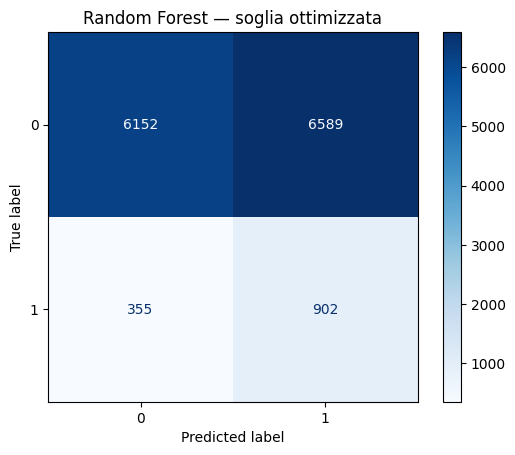

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Dummy,0.910,0.000,0.000,0.000,0.500,0.090
DT libero,0.836,0.140,0.161,0.150,0.532,0.098
DT bilanciato,0.606,0.127,0.574,0.208,0.632,0.159
DT ottimizzato,0.604,0.127,0.583,0.209,0.638,0.164
Logistic Regression,0.660,0.137,0.526,0.217,0.647,0.165
Random Forest,0.703,0.150,0.493,0.230,0.654,0.176
LR + SMOTE,0.910,0.300,0.005,0.009,0.621,0.151
RF soglia ottimizzata,0.504,0.120,0.718,0.206,0.654,0.176


In [34]:
p_test = rf.predict_proba(X_test)[:, 1]
y_pred_soglia = (p_test >= soglia).astype(int)

risultati['RF soglia ottimizzata'] = {
    'Accuracy':  accuracy_score(y_test, y_pred_soglia),
    'Precision': precision_score(y_test, y_pred_soglia),
    'Recall':    recall_score(y_test, y_pred_soglia),
    'F1':        f1_score(y_test, y_pred_soglia),
    'ROC-AUC':   roc_auc_score(y_test, p_test),
    'PR-AUC':    average_precision_score(y_test, p_test)}
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_soglia, cmap='Blues')
plt.title('Random Forest — soglia ottimizzata'); plt.show()
pd.DataFrame(risultati).T.round(3)

### Cella 35 — Importanza delle feature (Random Forest)

Visualizziamo le 15 feature più importanti per la Random Forest. Le prime sono la dimissione a casa e `number_inpatient`, cioè le stesse variabili emerse nell'analisi esplorativa, seguite da durata del ricovero, numero di esami e di farmaci ed età. Questa misura ha però dei limiti: favorisce le variabili numeriche, che offrono più split possibili, e non indica se una feature aumenta o riduce il rischio.

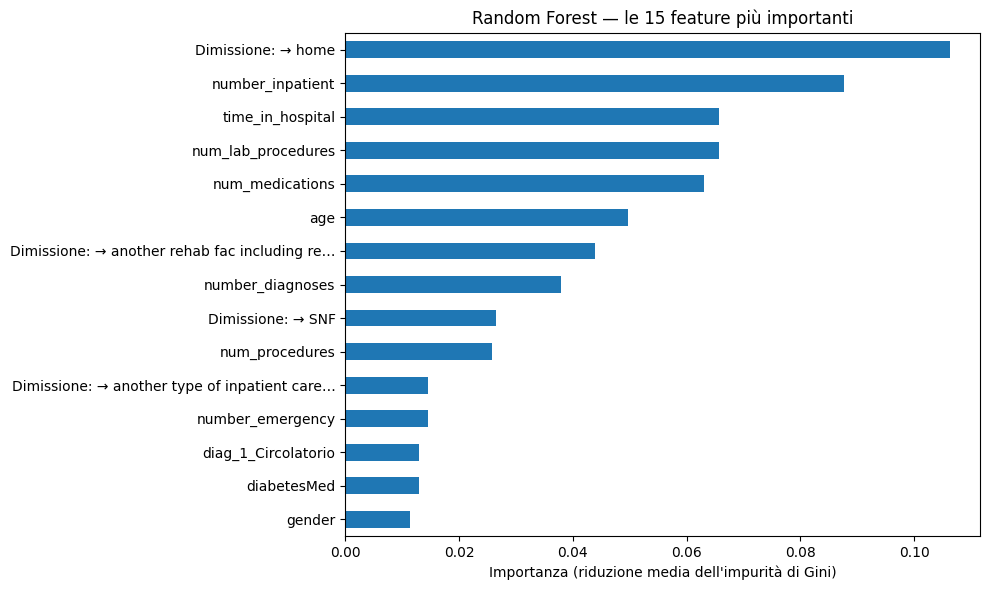

In [35]:
def nome_breve(n, max_len=45):
    # Accorcia i nomi delle colonne one-hot per renderli leggibili nei grafici
    for vecchio, nuovo in [('discharge_disposition_id_desc_', 'Dimissione: '),
                           ('admission_source_id_desc_', 'Provenienza: '),
                           ('admission_type_id_desc_', 'Tipo ricovero: '),
                           ('medical_specialty_', 'Specialità: '),
                           ('Discharged/transferred to ', '→ '), ('Discharged to ', '→ ')]:
        n = n.replace(vecchio, nuovo)
    return n if len(n) <= max_len else n[:max_len - 1] + '…'

imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
top_imp = imp.head(15).sort_values()
top_imp.index = top_imp.index.map(nome_breve)

top_imp.plot.barh(figsize=(10, 6))
plt.xlabel("Importanza (riduzione media dell'impurità di Gini)")
plt.title('Random Forest — le 15 feature più importanti')
plt.tight_layout(); plt.show()

### Cella 36 — Coefficienti della Logistic Regression

Visualizziamo i coefficienti più grandi della regressione logistica, che indicano anche la direzione dell'effetto. Il segnale più chiaro riguarda la dimissione: il trasferimento in riabilitazione o in un'altra struttura aumenta il rischio, il ritorno a casa lo riduce, in accordo con la Random Forest. Alcuni coefficienti non vanno interpretati: "Tipo ricovero: Altro" (−2,35) e `diag_1_Missing` (+1,04) riguardano categorie con pochissimi pazienti e sono instabili; le altre categorie del tipo di ricovero risultano positive solo perché vanno lette in rapporto ad "Altro".

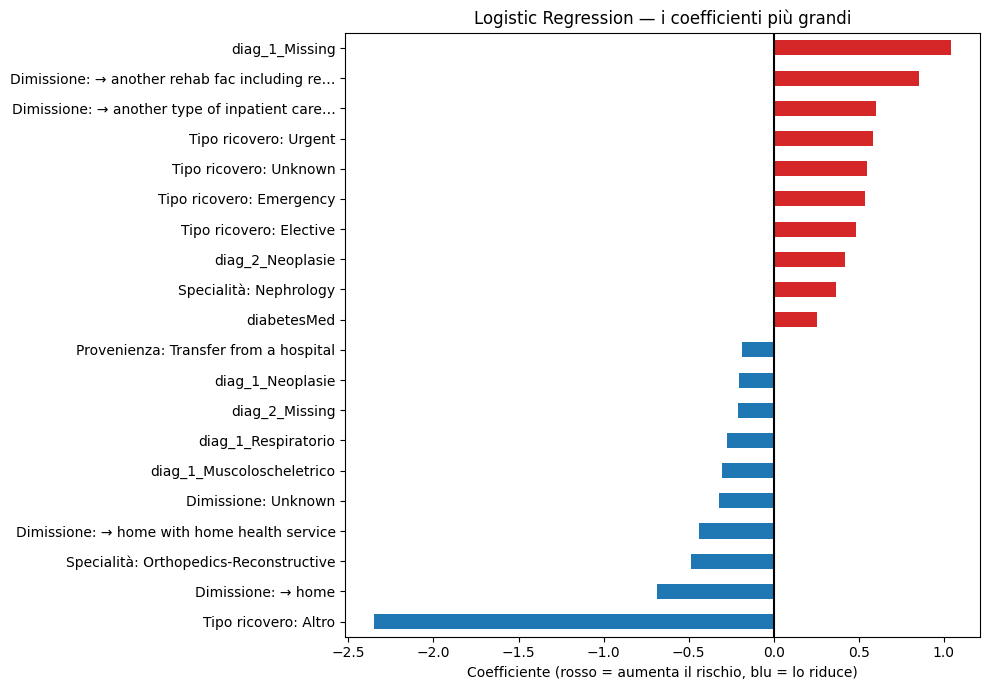

In [36]:
coef = pd.Series(lr.coef_[0], index=X_train_sc.columns).sort_values()
top = pd.concat([coef.head(10), coef.tail(10)])
top.index = top.index.map(nome_breve)

top.plot.barh(figsize=(10, 7), color=['tab:blue' if c < 0 else 'tab:red' for c in top])
plt.axvline(0, color='k')
plt.xlabel('Coefficiente (rosso = aumenta il rischio, blu = lo riduce)')
plt.title('Logistic Regression — i coefficienti più grandi')
plt.tight_layout(); plt.show()

### Cella 37 — Analisi dei tipi di errore

Dividiamo i pazienti del test nei quattro esiti della matrice di confusione e ne confrontiamo il profilo medio. I riammessi persi (falsi negativi) sono quasi identici ai pazienti correttamente non segnalati: quasi nessun ricovero precedente, degenza di circa 3 giorni, 94% dimessi a casa; con le variabili disponibili sono indistinguibili. I falsi allarmi assomigliano invece ai riammessi riconosciuti: degenze più lunghe, più farmaci ed esami, solo un terzo dimessi a casa. Il modello ha quindi imparato il profilo del paziente clinicamente complesso: il limite principale è nei dati, che non contengono informazioni su ciò che accade dopo la dimissione.

In [37]:
yt = y_test.values
tipo = np.select(
    [(yt == 1) & (y_pred_soglia == 1),
     (yt == 1) & (y_pred_soglia == 0),
     (yt == 0) & (y_pred_soglia == 1)],
    ['TP (riammessi riconosciuti)', 'FN (riammessi persi)', 'FP (falsi allarmi)'],
    default='TN (non riammessi, non segnalati)')

profilo = X_test[num_cols + ['age']].copy()
col_casa = [c for c in X_test.columns if 'Discharged to home' in c][0]
profilo['dimesso_a_casa'] = X_test[col_casa]
profilo['tipo'] = tipo

print(profilo['tipo'].value_counts(), '\n')
profilo.groupby('tipo').mean().round(2).T

tipo
FP (falsi allarmi)                   6589
TN (non riammessi, non segnalati)    6152
TP (riammessi riconosciuti)           902
FN (riammessi persi)                  355
Name: count, dtype: int64 



tipo,FN (riammessi persi),FP (falsi allarmi),"TN (non riammessi, non segnalati)",TP (riammessi riconosciuti)
time_in_hospital,3.09,5.37,2.99,5.35
num_lab_procedures,40.17,47.03,37.12,47.59
num_procedures,1.26,1.50,1.39,1.47
num_medications,13.58,17.76,13.14,17.89
number_outpatient,0.18,0.35,0.20,0.36
number_emergency,0.05,0.14,0.06,0.17
number_inpatient,0.02,0.29,0.01,0.53
number_diagnoses,6.81,7.90,6.45,7.86
age,5.62,6.58,5.44,6.55
dimesso_a_casa,0.94,0.38,0.94,0.33
